<a href="https://colab.research.google.com/github/Abhi02-Sathikumar/CROP_YIELD_PREDICTION/blob/main/notebooks/CropRecommendation_intern_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [21]:
import os

# Verification that dataset exists locally
file_path = '/content/Crop_recommendation.csv'
if os.path.exists(file_path):
    print(f"Success! '{file_path}' is available and ready for analysis.")
else:
    print(f"Warning: '{file_path}' was not found.")

Saving Crop_recommendation.csv to Crop_recommendation (2).csv


In [22]:
import urllib.request

# Download the genuine raw CSV file from a verified source
url = 'https://raw.githubusercontent.com/Gladiator07/Harvestify/master/Data-processed/crop_recommendation.csv'
try:
    urllib.request.urlretrieve(url, '/content/Crop_recommendation.csv')
    print('Raw dataset downloaded successfully!')
except Exception as e:
    # Fallback raw link if the above path structure changes
    fallback_url = 'https://raw.githubusercontent.com/laxmimerit/All-CSV-ML-Data-Files-Download/master/Crop_recommendation.csv'
    urllib.request.urlretrieve(fallback_url, '/content/Crop_recommendation.csv')
    print('Raw dataset downloaded successfully from fallback source!')

Raw dataset downloaded successfully!


In [23]:
import pandas as pd
crop_rec = pd.read_csv("/content/Crop_recommendation.csv")

print("Shape:", crop_rec.shape)
display(crop_rec.head())

Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [24]:
with open("/content/Crop_recommendation.csv", "r", encoding="utf-8-sig") as f:
    for i in range(25):
        print(f"{i+1}: {f.readline().rstrip()}")

1: N,P,K,temperature,humidity,ph,rainfall,label
2: 90,42,43,20.87974371,82.00274423,6.502985292000001,202.9355362,rice
3: 85,58,41,21.77046169,80.31964408,7.038096361,226.6555374,rice
4: 60,55,44,23.00445915,82.3207629,7.840207144,263.9642476,rice
5: 74,35,40,26.49109635,80.15836264,6.980400905,242.8640342,rice
6: 78,42,42,20.13017482,81.60487287,7.628472891,262.7173405,rice
7: 69,37,42,23.05804872,83.37011772,7.073453503,251.0549998,rice
8: 69,55,38,22.70883798,82.63941394,5.70080568,271.3248604,rice
9: 94,53,40,20.27774362,82.89408619,5.718627177999999,241.9741949,rice
10: 89,54,38,24.51588066,83.53521629999999,6.685346424,230.4462359,rice
11: 68,58,38,23.22397386,83.03322691,6.336253525,221.2091958,rice
12: 91,53,40,26.52723513,81.41753846,5.386167788,264.6148697,rice
13: 90,46,42,23.97898217,81.45061596,7.50283396,250.0832336,rice
14: 78,58,44,26.80079604,80.88684822,5.108681786,284.4364567,rice
15: 93,56,36,24.01497622,82.05687182,6.98435366,185.2773389,rice
16: 94,50,37,25.665852

In [25]:
crop_rec = pd.read_csv("/content/Crop_recommendation.csv")
print(crop_rec.shape)
crop_rec.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [26]:
print("Shape:", crop_rec.shape)

Shape: (2200, 8)


In [27]:
crop_rec.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [28]:
crop_rec.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [29]:
crop_rec["label"] = crop_rec["label"].str.strip().str.lower()
print(crop_rec["label"].unique())

['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [30]:
crop_rec.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [31]:
(crop_rec.isnull().sum() / len(crop_rec) * 100).round(2)

,0
N,0.0
P,0.0
K,0.0
temperature,0.0
humidity,0.0
ph,0.0
rainfall,0.0
label,0.0


In [32]:
print("Duplicate rows:", crop_rec.duplicated().sum())

Duplicate rows: 0


In [33]:
numeric_columns = [
    "N", "P", "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

for col in numeric_columns:
    print(f"\n{col}")
    print("Minimum:", crop_rec[col].min())
    print("Maximum:", crop_rec[col].max())


N
Minimum: 0
Maximum: 140

P
Minimum: 5
Maximum: 145

K
Minimum: 5
Maximum: 205

temperature
Minimum: 8.825674745
Maximum: 43.67549305

humidity
Minimum: 14.25803981
Maximum: 99.98187601

ph
Minimum: 3.504752314
Maximum: 9.93509073

rainfall
Minimum: 20.21126747
Maximum: 298.5601175


In [34]:
crop_rec["label"].value_counts()

,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


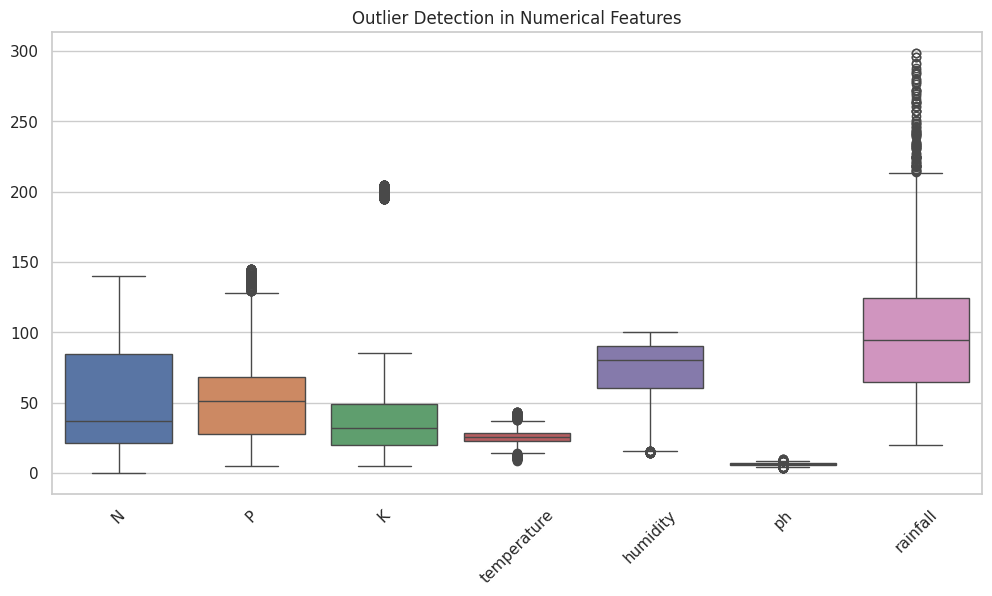

In [35]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=crop_rec[
        ["N", "P", "K", "temperature",
         "humidity", "ph", "rainfall"]
    ]
)

plt.title("Outlier Detection in Numerical Features")
plt.xticks(rotation=45)
plt.show()

In [36]:
for col in numeric_columns:
    Q1 = crop_rec[col].quantile(0.25)
    Q3 = crop_rec[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = crop_rec[
        (crop_rec[col] < lower) |
        (crop_rec[col] > upper)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

N: 0 potential outliers
P: 138 potential outliers
K: 200 potential outliers
temperature: 86 potential outliers
humidity: 30 potential outliers
ph: 57 potential outliers
rainfall: 100 potential outliers


In [37]:
correlation = crop_rec[numeric_columns].corr()
correlation

,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


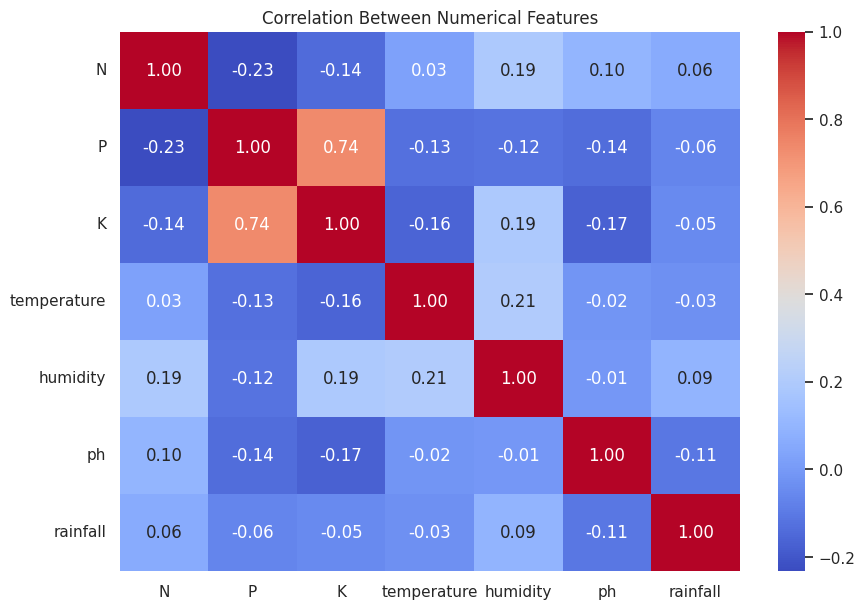

In [38]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [39]:
crop_rec.groupby("label")["N"].mean().sort_values(ascending=False)

,N
label,
cotton,117.77
coffee,101.20
muskmelon,100.32
banana,100.23
watermelon,99.42
rice,79.89
jute,78.40
maize,77.76
papaya,49.88


In [40]:
crop_rec.groupby("label")["P"].mean().sort_values(ascending=False)

,P
label,
apple,134.22
grapes,132.53
banana,82.01
lentil,68.36
chickpea,67.79
pigeonpeas,67.73
kidneybeans,67.54
blackgram,67.47
papaya,59.05


In [41]:
crop_rec.groupby("label")["K"].mean().sort_values(ascending=False)

,K
label,
grapes,200.11
apple,199.89
chickpea,79.92
watermelon,50.22
muskmelon,50.08
banana,50.05
papaya,50.04
pomegranate,40.21
jute,39.99


In [42]:
crop_rec.groupby("label")[
    ["temperature", "humidity", "ph", "rainfall"]
].mean()

,temperature,humidity,ph,rainfall
label,,,,
apple,22.630942,92.333383,5.929663,112.654779
banana,27.376798,80.358123,5.983893,104.626980
blackgram,29.973340,65.118426,7.133952,67.884151
chickpea,18.872847,16.860439,7.336957,80.058977
coconut,27.409892,94.844272,5.976562,175.686646
coffee,25.540477,58.869846,6.790308,158.066295
cotton,23.988958,79.843474,6.912675,80.398043
grapes,23.849575,81.875228,6.025937,69.611829
jute,24.958376,79.639864,6.732778,174.792798


In [43]:
print("Final shape:", crop_rec.shape)

print("\nMissing values:")
print(crop_rec.isnull().sum())

print("\nDuplicate rows:")
print(crop_rec.duplicated().sum())

print("\nData types:")
print(crop_rec.dtypes)

Final shape: (2200, 8)

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows:
0

Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object


In [44]:
crop_rec.to_csv(
    "/content/crop_recommendation_preprocessed.csv",
    index=False
)

print("Preprocessed Crop Recommendation Dataset Saved Successfully.")

Preprocessed Crop Recommendation Dataset Saved Successfully.


In [45]:
# Save the preprocessed dataset
import os

output_dir = "/content/CROP_YIELD_PREDICTION/data/processed_data"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "crop_recommendation_preprocessed.csv"
)

crop_rec.to_csv(output_path, index=False)

print(f"Dataset saved successfully: {output_path}")
print(f"Dataset shape: {crop_rec.shape}")

Dataset saved successfully: /content/CROP_YIELD_PREDICTION/data/processed_data/crop_recommendation_preprocessed.csv
Dataset shape: (2200, 8)
